# LightGCN на Gowalla и Yelp2018

Проект по дисциплине «Рекомендательные системы», подгруппа 6: Мещеряков Д.П., Соболь В.В.

Модель – LightGCN (He et al., SIGIR 2020, https://arxiv.org/abs/2002.02126), задача – top-K рекомендации по неявной обратной связи.
Наборы данных – Gowalla и Yelp2018 с Hugging Face в разбиениях из статьи. Метрика – Recall@20 (основная) и NDCG@20 при полном ранжировании.

Обучение запускается из командной строки (`train.py`, `run_all.sh`), здесь только разбор результатов из `results/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import Dataset

RES = Path("results")
NAMES = {"gowalla": "Gowalla", "yelp2018": "Yelp2018"}
PAPER = {"gowalla": (0.1823, 0.1555), "yelp2018": (0.0639, 0.0525)}
pd.set_option("display.precision", 4)


def load(tag):
    return json.loads((RES / f"{tag}.json").read_text(encoding="utf-8"))

## Данные

In [2]:
data = {d: Dataset(d) for d in NAMES}
pd.DataFrame({NAMES[d]: ds.stats() for d, ds in data.items()}).T

,users,items,train,test,density
Gowalla,29858.0,40981.0,810128.0,217242.0,0.0008
Yelp2018,31668.0,38048.0,1237259.0,324147.0,0.0013


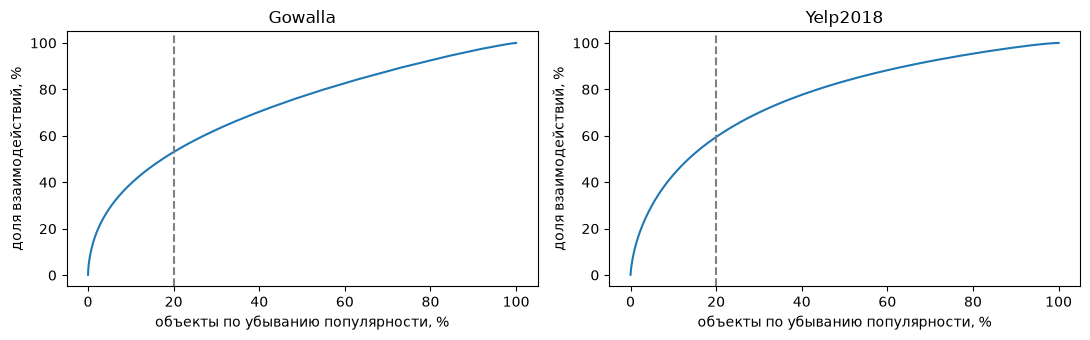

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (d, ds) in zip(axes, data.items()):
    pop = np.sort(ds.popularity)[::-1]
    ax.plot(np.arange(1, len(pop) + 1) / len(pop) * 100, np.cumsum(pop) / pop.sum() * 100)
    ax.axvline(20, ls="--", color="gray")
    ax.set_title(NAMES[d])
    ax.set_xlabel("объекты по убыванию популярности, %")
    ax.set_ylabel("доля взаимодействий, %")
plt.tight_layout()

## Основные результаты (1000 эпох, модель с последней эпохи)

In [4]:
rows = []
for d in NAMES:
    for name, tag in [("MostPop", "pop"), ("MF-BPR", "k0"), ("LightGCN, K=3", "k3")]:
        f = load(f"{d}_{tag}")["final"]
        rows.append({"набор": NAMES[d], "модель": name, "Recall@20": f["recall@20"], "NDCG@20": f["ndcg@20"]})
    rows.append({"набор": NAMES[d], "модель": "LightGCN, K=3, статья", "Recall@20": PAPER[d][0], "NDCG@20": PAPER[d][1]})
pd.DataFrame(rows)

,набор,модель,Recall@20,NDCG@20
0,Gowalla,MostPop,0.0416,0.0317
1,Gowalla,MF-BPR,0.1439,0.1144
2,Gowalla,"LightGCN, K=3",0.1821,0.1552
3,Gowalla,"LightGCN, K=3, статья",0.1823,0.1555
4,Yelp2018,MostPop,0.0125,0.0101
5,Yelp2018,MF-BPR,0.0473,0.0380
6,Yelp2018,"LightGCN, K=3",0.0636,0.0523
7,Yelp2018,"LightGCN, K=3, статья",0.0639,0.0525


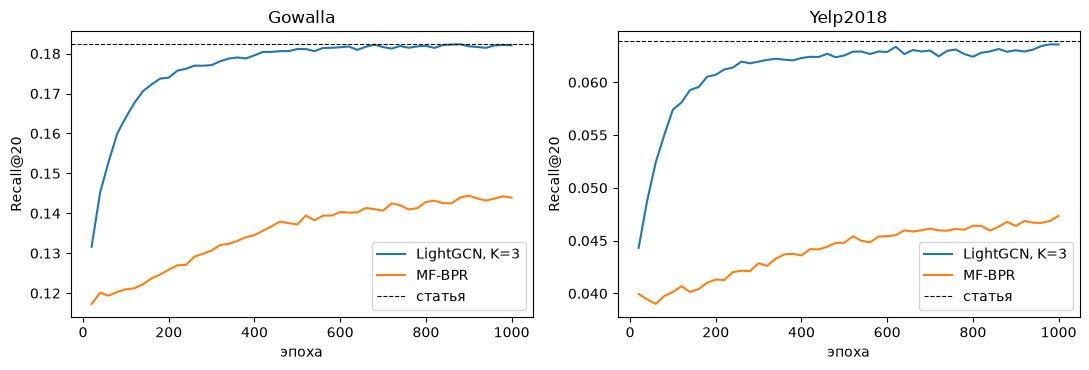

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, d in zip(axes, NAMES):
    for tag, label in [("k3", "LightGCN, K=3"), ("k0", "MF-BPR")]:
        h = [r for r in load(f"{d}_{tag}")["history"] if "recall@20" in r]
        ax.plot([r["epoch"] for r in h], [r["recall@20"] for r in h], label=label)
    ax.axhline(PAPER[d][0], ls="--", color="black", lw=0.8, label="статья")
    ax.set_title(NAMES[d])
    ax.set_xlabel("эпоха")
    ax.set_ylabel("Recall@20")
    ax.legend()
plt.tight_layout()

## Число слоев (одинаковый бюджет 200 эпох)

In [6]:
rows = []
for k in range(5):
    row = {"K": k}
    for d in NAMES:
        h = next(r for r in load(f"{d}_k{k}")["history"] if r["epoch"] == 200)
        row[f"{NAMES[d]} Recall@20"] = h["recall@20"]
        row[f"{NAMES[d]} NDCG@20"] = h["ndcg@20"]
    rows.append(row)
pd.DataFrame(rows).set_index("K")

,Gowalla Recall@20,Gowalla NDCG@20,Yelp2018 Recall@20,Yelp2018 NDCG@20
K,,,,
0,0.1259,0.1020,0.0413,0.0339
1,0.1610,0.1384,0.0531,0.0438
2,0.1733,0.1492,0.0590,0.0487
3,0.1740,0.1491,0.0607,0.0499
4,0.1721,0.1466,0.0602,0.0494


## Смещение к популярному

Покрытие – доля каталога, попавшая хотя бы в один топ-20. Доля популярных – доля 20 % самых популярных объектов среди всех рекомендаций (в тестовых данных для сравнения – `head_share_test`).

In [7]:
cols = ["recall@20", "coverage", "gini", "head_share_recs", "head_share_test", "tail_recall", "head_recall"]
rows = []
for d in NAMES:
    for name, tag in [("MostPop", "pop"), ("MF-BPR", "k0"), ("LightGCN", "k3")]:
        f = load(f"{d}_{tag}")["final"]
        rows.append({"набор": NAMES[d], "модель": name, **{c: f[c] for c in cols}})
pd.DataFrame(rows)

,набор,модель,recall@20,coverage,gini,head_share_recs,head_share_test,tail_recall,head_recall
0,Gowalla,MostPop,0.0416,0.0009,0.9995,1.0000,0.5183,0.0000,0.0736
1,Gowalla,MF-BPR,0.1439,0.6679,0.8170,0.7665,0.5183,0.0437,0.1861
2,Gowalla,LightGCN,0.1821,0.4311,0.9144,0.8782,0.5183,0.0363,0.2633
3,Yelp2018,MostPop,0.0125,0.0012,0.9995,1.0000,0.5132,0.0000,0.0200
4,Yelp2018,MF-BPR,0.0473,0.5931,0.8294,0.8369,0.5132,0.0120,0.0699
5,Yelp2018,LightGCN,0.0636,0.4092,0.9124,0.9323,0.5132,0.0089,0.1006


In [8]:
pd.DataFrame([{"набор": NAMES[d], **g} for d in NAMES for g in load(f"{d}_k3")["final"]["by_activity"]])

,набор,group,min,max,users,recall@20,ndcg@20
0,Gowalla,1,8,10,7368,0.2103,0.1389
1,Gowalla,2,11,15,6874,0.1959,0.1427
2,Gowalla,3,16,28,8131,0.1791,0.1547
3,Gowalla,4,29,811,7485,0.1449,0.1834
4,Yelp2018,1,16,18,7131,0.0710,0.0471
5,Yelp2018,2,19,24,8086,0.0678,0.0475
6,Yelp2018,3,25,40,8397,0.0643,0.0511
7,Yelp2018,4,41,1848,8054,0.0520,0.0631


Штраф за популярность при ранжировании: `score - alpha * log(1 + pop)` (`rerank.py`).

In [9]:
rows = [{"набор": NAMES[d], **r} for d in NAMES
        for r in json.loads((RES / f"{d}_k3_rerank.json").read_text(encoding="utf-8"))]
pd.DataFrame(rows)[["набор", "alpha", "recall@20", "ndcg@20", "coverage", "head_share_recs", "tail_recall"]]

,набор,alpha,recall@20,ndcg@20,coverage,head_share_recs,tail_recall
0,Gowalla,0.00,0.1821,0.1552,0.4311,0.8782,0.0363
1,Gowalla,0.10,0.1820,0.1552,0.4699,0.8623,0.0394
2,Gowalla,0.20,0.1820,0.1551,0.5100,0.8442,0.0423
3,Gowalla,0.30,0.1816,0.1548,0.5508,0.8235,0.0454
4,Gowalla,0.50,0.1790,0.1531,0.6422,0.7710,0.0515
5,Gowalla,0.75,0.1726,0.1484,0.7492,0.6828,0.0602
6,Gowalla,1.00,0.1626,0.1400,0.8293,0.5710,0.0697
7,Yelp2018,0.00,0.0636,0.0523,0.4092,0.9323,0.0089
8,Yelp2018,0.10,0.0636,0.0524,0.4397,0.9192,0.0101
9,Yelp2018,0.20,0.0633,0.0522,0.4753,0.9029,0.0113


## Пример выдачи

Для случайного пользователя Gowalla из тестовой выборки: топ-10 LightGCN, популярность объекта в обучении и попал ли он в тест. Нужны сохраненные векторы `runs/gowalla_k3.pt` (`train.py --save-runs`).

In [10]:
import torch
from model import LightGCN

ds = data["gowalla"]
model = LightGCN(ds.n_users, ds.n_items, ds.norm_adj("cpu"))
model.emb.load_state_dict(torch.load("runs/gowalla_k3.pt", map_location="cpu"))
with torch.no_grad():
    u_emb, i_emb = model.propagate()

u = int(np.random.default_rng(7).choice(np.flatnonzero(np.diff(ds.test.indptr))))
scores = (u_emb[u] @ i_emb.T).numpy()
scores[ds.train[u].indices] = -np.inf
top = np.argsort(-scores)[:10]
test_items = set(ds.test[u].indices)
print("пользователь", u, "| в обучении", ds.train[u].nnz, "| в тесте", len(test_items))
pd.DataFrame({"объект": top, "оценка": scores[top], "популярность": ds.popularity[top].astype(int),
              "в тесте": [i in test_items for i in top]})

пользователь 28212 | в обучении 9 | в тесте 3


,объект,оценка,популярность,в тесте
0,2337,8.4113,1031,False
1,8239,8.1749,46,False
2,12953,8.0348,42,False
3,1811,8.0267,856,True
4,2635,7.8267,330,True
5,22003,7.2895,26,False
6,18520,7.2789,49,False
7,16437,7.0813,45,False
8,16421,6.8904,52,False
9,8240,6.7084,12,False
